# Week 11 Benchmark Analysis

Use only the supplied synthetic data. Preserve the raw CSV unchanged and perform every transformation in code.

## Analysis question

**Which clinics and referral services have the lowest on-time follow-up completion rates, and where should the program focus its next quality-improvement review?**

For this assignment:

- The analysis snapshot is `2026-10-31`.
- A referral is **completed** when `completion_date` is present.
- A referral is **on time** when it has a completion date on or before its due date.
- The required on-time rate uses **all referrals in the group** as the denominator. Pending referrals therefore remain in the denominator.

Work through the notebook in order. Each section separates observation, transformation, verification, and interpretation so that your decisions remain traceable. Complete every TODO, record cleaning decisions in the cleaning log, and restart the runtime and run all cells before submitting.


In [1]:
from pathlib import Path
import pandas as pd
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt

RAW_PATH = Path("Week11_Messy_Followup_Data.csv")
CLEAN_PATH = Path("Week11_Cleaned_Followup_Data.csv")
SNAPSHOT = pd.Timestamp("2026-10-31")


## 1 Load the raw data and create a working copy

The raw file is evidence of what was received. Do not overwrite it or clean it manually. Load it as `df_raw`, then create a separate copy named `df` for all cleaning and analysis.

The analytic grain is **one row per referral record**. A patient may legitimately have more than one referral, so `patient_id` is not the duplicate key. `record_id` identifies the synthetic source referral row.


In [2]:
from hashlib import sha256

raw_digest = sha256(RAW_PATH.read_bytes()).hexdigest()
df_raw = pd.read_csv(RAW_PATH, dtype={"record_id": "string", "patient_id": "string"})
df = df_raw.copy(deep=True)

print("Raw shape:", df_raw.shape)
print("Working shape:", df.shape)
print("Separate DataFrame objects:", df is not df_raw)
assert df_raw.shape == (42, 9)

Raw shape: (42, 9)
Working shape: (42, 9)
Separate DataFrame objects: True


### 1.1 Inspect structure and data types

Start with the dataset's size, column names, first records, and data types. Do not assume that a date-looking or number-looking column was imported with the correct type.

Questions to consider:

- Are all fields from the data dictionary present?
- Which date fields were imported as text?
- Which numeric field may contain a value that prevents numeric import?


In [3]:
# Run this cell before cleaning.
print("Rows and columns:", df_raw.shape)
print("Column names:", df_raw.columns.tolist())
display(df_raw.head())

print("\nImported data types:")
display(df_raw.dtypes.to_frame("dtype"))


Rows and columns: (42, 9)
Column names: ['record_id', 'patient_id', 'clinic', 'referral_service', 'referral_date', 'due_date', 'completion_date', 'social_needs_flag', 'contact_attempts']


,record_id,patient_id,clinic,referral_service,referral_date,due_date,completion_date,social_needs_flag,contact_attempts
0,Q001,P001,NORTHSIDE CLINIC,medication review,08/03/2026,08/17/2026,08/13/2026,1,1
1,Q002,P002,Riverbend Clinic,Social work,2026-08-05,2026-08-19,2026-08-18,0,2
2,Q003,P003,Mountain View Clinic,Nutrition,2026-08-07,2026-08-14,2026-08-14,0,3
3,Q004,P004,Northside Clinic,Care coordination,2026-08-09,2026-08-23,2026-08-21,0,1
4,Q005,P005,Riverbend Clinic,Medication review,2026-08-11,2026-08-25,2026-08-26,1,2



Imported data types:


,dtype
record_id,string
patient_id,string
clinic,str
referral_service,str
referral_date,str
due_date,str
completion_date,str
social_needs_flag,int64
contact_attempts,str


### 1.2 Quantify missingness and possible duplicates

Use more than one duplicate check:

- `df_raw.duplicated()` identifies rows that are exact copies across every column.
- Repeated `record_id` values help verify which referral rows were duplicated.
- Do **not** remove records merely because `patient_id` repeats; a patient can have multiple valid referrals.


In [4]:
missing_before = df_raw.isna().sum().to_frame("missing_count")
missing_before["missing_percent"] = (
    missing_before["missing_count"] / len(df_raw) * 100
)
display(missing_before)

exact_duplicate_count = int(df_raw.duplicated().sum())
print("Exact duplicate rows:", exact_duplicate_count)

duplicate_record_ids = df_raw.loc[
    df_raw["record_id"].duplicated(keep=False), "record_id"
].value_counts()
print("\nRepeated record_id values:")
display(duplicate_record_ids)


,missing_count,missing_percent
record_id,0,0.000000
patient_id,0,0.000000
clinic,0,0.000000
referral_service,1,2.380952
referral_date,0,0.000000
due_date,0,0.000000
completion_date,7,16.666667
social_needs_flag,0,0.000000
contact_attempts,0,0.000000


Exact duplicate rows: 2

Repeated record_id values:


record_id
Q005    2
Q020    2
Name: count, dtype: Int64

### 1.3 Examine category and numeric values

Category variants may differ only by capitalization or spacing. A frequency table makes these differences easier to see than scanning the full dataset. Include missing values so they are not silently excluded.

Also inspect `contact_attempts`. A text value in that field is not automatically equivalent to a number, even when a reader can infer what the text probably means.


In [5]:
for column in ["clinic", "referral_service", "social_needs_flag", "contact_attempts"]:
    print(f"\n{column}")
    display(df_raw[column].value_counts(dropna=False).to_frame("rows"))



clinic


,rows
clinic,
Riverbend Clinic,13
Mountain View Clinic,12
Northside Clinic,12
NORTHSIDE CLINIC,2
MOUNTAIN VIEW CLINIC,1
River Bend Clinic,1
RIVERBEND CLINIC,1



referral_service


,rows
referral_service,
Care coordination,10
Nutrition,9
Medication review,9
Social work,8
medication review,2
social work,1
NaN,1
nutrition,1
care coordination,1



social_needs_flag


,rows
social_needs_flag,
0,26
1,16



contact_attempts


,rows
contact_attempts,
3,17
1,12
2,12
two,1


### 1.4 Examine the original date patterns

The three date fields contain more than one text format. Inspect representative values before parsing them. Later, `errors="coerce"` will convert values that cannot be parsed to missing timestamps (`NaT`), which lets you count and review failures rather than silently treating invalid text as a date.


In [6]:
date_columns = ["referral_date", "due_date", "completion_date"]

for column in date_columns:
    examples = sorted(df_raw[column].dropna().astype(str).unique())
    print(f"\n{column}: {len(examples)} distinct nonmissing values")
    print("First five examples:", examples[:5])
    print("Last five examples:", examples[-5:])



referral_date: 40 distinct nonmissing values
First five examples: ['08/03/2026', '08/15/2026', '08/27/2026', '09/08/2026', '09/20/2026']
Last five examples: ['2026-10-10', '2026-10-12', '2026-10-16', '2026-10-18', '2026-10-20']

due_date: 40 distinct nonmissing values
First five examples: ['08/17/2026', '08/29/2026', '09/10/2026', '09/22/2026', '10/04/2026']
Last five examples: ['2026-10-22', '2026-10-24', '2026-10-25', '2026-10-30', '2026-11-03']

completion_date: 31 distinct nonmissing values
First five examples: ['08/13/2026', '09/08/2026', '09/18/2026', '10/04/2026', '10/14/2026']
Last five examples: ['2026-10-19', '2026-10-22', '2026-10-25', '2026-10-29', '2026-11-01']


### Pre-cleaning observations

| Issue | Evidence from the raw data | Planned handling |
|---|---|---|
| Exact duplicates | Q005 and Q020 each occur twice. | Remove one exact copy of each. |
| Clinic labels | Three all-caps forms and the spelling “River Bend Clinic.” | Map variants to the three approved names. |
| Service labels | Four lowercase variants and one blank service (Q018). | Standardize case and label the blank Unknown. |
| Date formats | The three date columns import as text with ISO and U.S. month-first forms. Seven completion dates are blank. | Parse both formats and compare missing counts before and after. |
| Contact attempts | Q023 contains the text “two,” causing the column to import as text. | Coerce invalid numeric input to missing and retain the referral. |

A patient can have several distinct referrals. For example, P001 has Q001 and Q031. The referral record is the analytic unit, so exact duplicates are checked across all fields and remaining record IDs are verified as unique.

## 2 Clean and document the data

Clean one issue at a time. After each transformation, inspect or count the result before moving forward. Keep the original columns `clinic` and `referral_service`; create `clinic_clean` and `service_clean` so the standardized values can be compared with the source values.


### 2.1 Remove exact duplicate rows

Use `drop_duplicates()` on the complete row. Calculate the number removed by comparing the row count immediately before and after the operation. The raw `df_raw` object should remain unchanged.


In [7]:
rows_before_deduplication = len(df)

df = df.drop_duplicates().copy()

rows_after_deduplication = len(df)
rows_removed = rows_before_deduplication - rows_after_deduplication

print("Rows before:", rows_before_deduplication)
print("Rows after:", rows_after_deduplication)
print("Exact duplicate rows removed:", rows_removed)
print("Remaining repeated record_id values:", int(df["record_id"].duplicated().sum()))

Rows before: 42
Rows after: 40
Exact duplicate rows removed: 2
Remaining repeated record_id values: 0


### 2.2 Standardize clinic and service labels

The approved clinic labels are:

- `Northside Clinic`
- `Riverbend Clinic`
- `Mountain View Clinic`

The approved named service labels are:

- `Medication review`
- `Social work`
- `Nutrition`
- `Care coordination`

Use mapping dictionaries rather than a long series of row-by-row conditionals. Strip extra spaces and use case-insensitive matching where appropriate. A missing service is a data-quality issue, but the referral must remain in the overall total; label that service `Unknown`.


In [8]:
clinic_map = {
    "Northside Clinic": "Northside Clinic",
    "NORTHSIDE CLINIC": "Northside Clinic",
    "Riverbend Clinic": "Riverbend Clinic",
    "RIVERBEND CLINIC": "Riverbend Clinic",
    "River Bend Clinic": "Riverbend Clinic",
    "Mountain View Clinic": "Mountain View Clinic",
    "MOUNTAIN VIEW CLINIC": "Mountain View Clinic",
}
approved_services = [
    "Medication review", "Social work", "Nutrition", "Care coordination"
]
service_map = {label.casefold(): label for label in approved_services}

df["clinic_clean"] = df["clinic"].str.strip().map(clinic_map)
service_key = df["referral_service"].fillna("").str.strip().str.casefold()
assert service_key[service_key.ne("")].isin(service_map).all()
df["service_clean"] = service_key.map(service_map).fillna("Unknown")

#### Category-mapping checkpoint

Run this after creating the cleaned category columns. An empty unmatched-clinic table confirms that every observed clinic variant was mapped. The clinic cross-tab also documents exactly how raw labels changed.


In [9]:
unmatched_clinics = df.loc[df["clinic_clean"].isna(), "clinic"].value_counts(dropna=False)
print("Unmatched clinic labels (should be empty):")
display(unmatched_clinics)

print("Raw-to-clean clinic mapping:")
display(pd.crosstab(df["clinic"], df["clinic_clean"], dropna=False))

print("Raw-to-clean service mapping:")
display(pd.crosstab(df["referral_service"].fillna("<missing>"), df["service_clean"], dropna=False))


Unmatched clinic labels (should be empty):


Series([], Name: count, dtype: int64)

Raw-to-clean clinic mapping:


clinic_clean,Mountain View Clinic,Northside Clinic,Riverbend Clinic
clinic,,,
MOUNTAIN VIEW CLINIC,1,0,0
Mountain View Clinic,12,0,0
NORTHSIDE CLINIC,0,2,0
Northside Clinic,0,12,0
RIVERBEND CLINIC,0,0,1
River Bend Clinic,0,0,1
Riverbend Clinic,0,0,11


Raw-to-clean service mapping:


service_clean,Care coordination,Medication review,Nutrition,Social work,Unknown
referral_service,,,,,
<missing>,0,0,0,0,1
Care coordination,9,0,0,0,0
Medication review,0,8,0,0,0
Nutrition,0,0,9,0,0
Social work,0,0,0,8,0
care coordination,1,0,0,0,0
medication review,0,2,0,0,0
nutrition,0,0,1,0,0
social work,0,0,0,1,0


### 2.3 Parse the date fields

Convert `referral_date`, `due_date`, and `completion_date` to pandas datetime values. Use `format="mixed"` because the supplied data contain both `MM/DD/YYYY` and `YYYY-MM-DD`. Use `errors="coerce"` so invalid text becomes `NaT` and can be reviewed.

Compare missing counts before and after parsing. For `completion_date`, preexisting blanks are meaningful: they represent referrals not completed at the snapshot. A rise in missingness after parsing would indicate an additional unparseable value.


In [10]:
date_missing_before = df[date_columns].isna().sum()

for column in date_columns:
    df[column] = pd.to_datetime(df[column], format="mixed", errors="coerce")

date_missing_after = df[date_columns].isna().sum()
date_parse_check = pd.DataFrame({
    "missing_before": date_missing_before,
    "missing_after": date_missing_after,
    "new_missing_after_parse": date_missing_after - date_missing_before,
})
display(date_parse_check)
print("Parsed date data types:")
display(df[date_columns].dtypes.to_frame("dtype"))

,missing_before,missing_after,new_missing_after_parse
referral_date,0,0,0
due_date,0,0,0
completion_date,7,7,0


Parsed date data types:


,dtype
referral_date,datetime64[us]
due_date,datetime64[us]
completion_date,datetime64[us]


### 2.4 Convert contact attempts to numeric

Preserve a copy of the original values for verification. Then use `pd.to_numeric(..., errors="coerce")`. Do not replace an unexpected text value with an inferred number; converting it to missing makes the uncertainty visible.


In [11]:
contact_attempts_raw = df["contact_attempts"].copy()
missing_contact_before = int(contact_attempts_raw.isna().sum())

df["contact_attempts"] = pd.to_numeric(contact_attempts_raw, errors="coerce")

missing_contact_after = int(df["contact_attempts"].isna().sum())
new_invalid_contact_values = missing_contact_after - missing_contact_before

print("Missing before numeric conversion:", missing_contact_before)
print("Missing after numeric conversion:", missing_contact_after)
print("New missing values caused by conversion:", new_invalid_contact_values)
print("Original values that did not parse:")
display(contact_attempts_raw[df["contact_attempts"].isna()].value_counts(dropna=False))

Missing before numeric conversion: 0
Missing after numeric conversion: 1
New missing values caused by conversion: 1
Original values that did not parse:


contact_attempts
two    1
Name: count, dtype: int64

### 2.5 Create completion and on-time indicators

Create two Boolean fields:

- `completed` is `True` when `completion_date` is not missing.
- `on_time` is `True` only when the referral is completed **and** `completion_date` is on or before `due_date`.

The required rate later divides the number of `True` values in `on_time` by **all referrals in the group**, not only completed referrals. This is why it is important to keep `completed` and `on_time` as separate fields.


In [12]:
df["completed"] = df["completion_date"].notna()
df["on_time"] = df["completed"] & df["completion_date"].le(df["due_date"])

print("Completed value counts:")
display(df["completed"].value_counts(dropna=False))
print("On-time value counts:")
display(df["on_time"].value_counts(dropna=False))
display(pd.crosstab(df["completed"], df["on_time"], margins=True))

print("Recorded completions after the snapshot:")
display(df.loc[df["completion_date"].gt(SNAPSHOT),
               ["record_id", "clinic_clean", "service_clean", "completion_date", "due_date"]])

Completed value counts:


completed
True     33
False     7
Name: count, dtype: int64

On-time value counts:


on_time
True     20
False    20
Name: count, dtype: int64

on_time,False,True,All
completed,,,
False,7,0,7
True,13,20,33
All,20,20,40


Recorded completions after the snapshot:


,record_id,clinic_clean,service_clean,completion_date,due_date
39,Q040,Northside Clinic,Care coordination,2026-11-01,2026-11-03


### 2.6 Required cleaning checks

These checks verify the minimum expected structure. Do not edit the expected values. If a check fails, return to the relevant cleaning step rather than deleting the assertion.


In [13]:
# Required checks: do not change the expected values.
assert df_raw.shape[0] == 42
assert int(df_raw.duplicated().sum()) == 2
assert df.shape[0] == 40
assert df["record_id"].nunique() == 40

assert set(df["clinic_clean"].dropna().unique()) == {
    "Northside Clinic", "Riverbend Clinic", "Mountain View Clinic"
}
assert set(df["service_clean"].unique()) == {
    "Medication review", "Social work", "Nutrition",
    "Care coordination", "Unknown"
}
assert all(pd.api.types.is_datetime64_any_dtype(df[column]) for column in date_columns)
assert pd.api.types.is_numeric_dtype(df["contact_attempts"])
assert pd.api.types.is_bool_dtype(df["completed"])
assert pd.api.types.is_bool_dtype(df["on_time"])
assert not (df["on_time"] & ~df["completed"]).any()

print("Core cleaning checks passed.")

assert df["clinic_clean"].notna().all()
assert not df.duplicated().any()
assert date_parse_check["new_missing_after_parse"].eq(0).all()
assert new_invalid_contact_values == 1

Core cleaning checks passed.


### Cleaning-log checkpoint

Before continuing, update `Week11_Cleaning_Log.md`. For each issue, record:

1. The evidence you observed.
2. The decision you made.
3. The number of rows affected.
4. The code or check that verified the result.

Include exact duplicates, clinic labels, service labels and missing service, date parsing, and contact-attempt conversion.


## 3 Calculate descriptive summaries

Build the analysis from individual quantities before grouping the data.

For the required measure:

\[
\text{on-time rate} = \frac{\text{referrals completed on or before the due date}}{\text{all referrals in the analyzed group}}
\]

Do not divide by completed referrals for the required rate. If you calculate that alternative rate for exploration, give it a different name and explain its denominator.


In [14]:
overall_referrals = len(df)
overall_completed = int(df["completed"].sum())
overall_on_time = int(df["on_time"].sum())
overall_on_time_rate = overall_on_time / overall_referrals

overall = {
    "referrals": overall_referrals,
    "completed": overall_completed,
    "on_time": overall_on_time,
    "on_time_rate": overall_on_time_rate,
}

display(pd.Series(overall, name="overall"))

referrals       40.0
completed       33.0
on_time         20.0
on_time_rate     0.5
Name: overall, dtype: float64

### 3.1 Create a reusable grouped-summary function

The same calculations are required for clinics, services, and the exploratory social-needs comparison. A function reduces repeated code and keeps the denominator consistent.

Inside the function:

1. Group by the requested column with `dropna=False`.
2. Count referrals using `record_id`.
3. Sum the Boolean `completed` and `on_time` fields; in pandas, `True` counts as 1.
4. Divide each group's on-time count by that group's referral count.
5. Sort from lowest to highest observed on-time rate.


In [15]:
def summarize(group_column):
    summary = (
        df.groupby(group_column, dropna=False)
          .agg(
              referrals=("record_id", "count"),
              completed=("completed", "sum"),
              on_time=("on_time", "sum"),
          )
    )

    summary["on_time_rate"] = summary["on_time"] / summary["referrals"]
    return summary.sort_values("on_time_rate", kind="stable")


clinic_summary = summarize("clinic_clean")
service_summary = summarize("service_clean")

print("Clinic summary:")
display(clinic_summary)
print("Service summary:")
display(service_summary)

Clinic summary:

,referrals,completed,on_time,on_time_rate
clinic_clean,,,,
Mountain View Clinic,13,10,3,0.230769
Riverbend Clinic,13,11,5,0.384615
Northside Clinic,14,12,12,0.857143


Service summary:


,referrals,completed,on_time,on_time_rate
service_clean,,,,
Unknown,1,1,0,0.000000
Care coordination,10,9,5,0.500000
Medication review,10,9,5,0.500000
Nutrition,10,7,5,0.500000
Social work,9,7,5,0.555556


### 3.2 Reconcile grouped totals to the overall result

Reconciliation checks whether records disappeared during grouping. Each summary should account for all referrals, completed referrals, and on-time referrals. This is especially important for the service summary because one source service is missing and must remain represented as `Unknown`.


In [16]:
# Required reconciliation checks: do not change these comparisons.
for name, summary in {
    "clinic": clinic_summary,
    "service": service_summary,
}.items():
    assert int(summary["referrals"].sum()) == overall_referrals, f"{name} referral total does not reconcile"
    assert int(summary["completed"].sum()) == overall_completed, f"{name} completed total does not reconcile"
    assert int(summary["on_time"].sum()) == overall_on_time, f"{name} on-time total does not reconcile"

print("Clinic and service totals reconcile to the overall result.")


Clinic and service totals reconcile to the overall result.


### 3.3 Explore the documented social-needs flag

Create a descriptive summary by `social_needs_flag` to support the required equity limitation. Treat this variable carefully: it indicates that a need was **documented**, not that it measures every person's circumstances or explains an outcome.

When interpreting the table, inspect group sizes and consider missing or unmeasured factors. Do not describe documented social needs as causing lower or higher performance.


In [17]:
social_needs_summary = summarize("social_needs_flag")
display(social_needs_summary)

for column in ["referrals", "completed", "on_time"]:
    assert int(social_needs_summary[column].sum()) == overall[column]
print("Social-needs totals reconcile to the overall result.")

,referrals,completed,on_time,on_time_rate
social_needs_flag,,,,
0,25,21,11,0.44
1,15,12,9,0.60


Social-needs totals reconcile to the overall result.


## 4 Create the visualizations

Create two bar charts that answer different parts of the analysis question:

1. On-time rate by clinic.
2. On-time rate by referral service.

Both charts need a zero baseline, a 0-to-1 y-axis, percent formatting, descriptive titles, labeled axes, readable category labels, and sufficient contrast. The service chart should show `Unknown` because excluding it would hide a data-quality issue; discuss why the one-record group should not be interpreted as meaningful performance evidence.


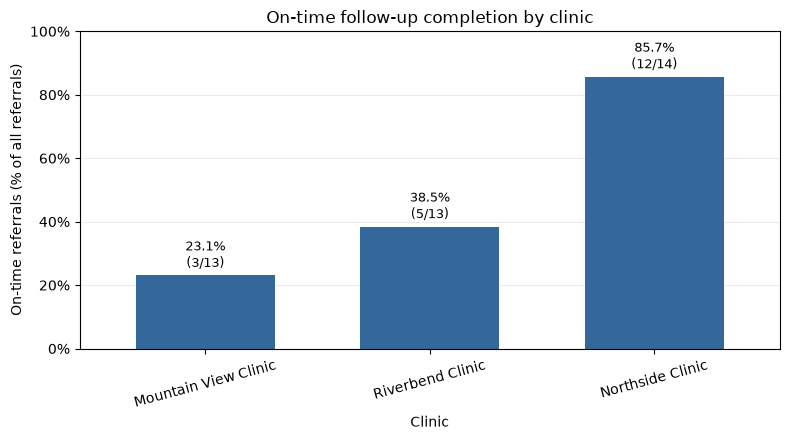

In [18]:
from matplotlib.ticker import PercentFormatter

def plot_rates(summary, category, color, path):
    ax = summary["on_time_rate"].plot.bar(
        figsize=(8, 4.5), color=color, width=0.62, ylim=(0, 1)
    )
    ax.set(title=f"On-time follow-up completion by {category}",
           xlabel=category.capitalize(), ylabel="On-time referrals (% of all referrals)")
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
    ax.tick_params(axis="x", labelrotation=15)
    ax.yaxis.grid(True, alpha=0.25)
    ax.set_axisbelow(True)
    labels = [f"{rate:.1%}\n({n}/{total})"
              for rate, n, total in summary[["on_time_rate", "on_time", "referrals"]]
              .itertuples(index=False, name=None)]
    ax.bar_label(ax.containers[0], labels=labels, padding=3, fontsize=9)
    figure = ax.get_figure()
    figure.tight_layout()
    figure.savefig(path, dpi=150)
    plt.show()
    plt.close(figure)

plot_rates(clinic_summary, "clinic", "#34689A", "Week11_Clinic_Rates.png")

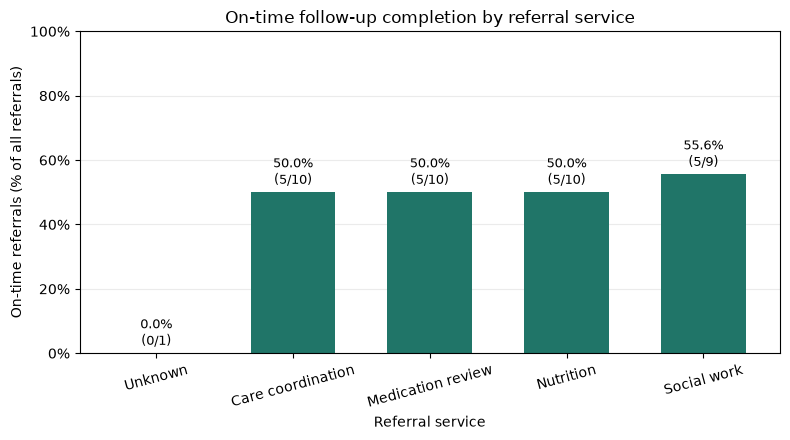

In [19]:
plot_rates(service_summary, "referral service", "#207568", "Week11_Service_Rates.png")

## 5 Extract evidence before interpreting

Use the summary tables to identify the lowest observed clinic rate. For the service comparison, report `Unknown` as a data-quality limitation but do not treat its single record as a meaningful service-performance finding. Compare the four named services when answering which service has the lowest observed rate.

Display the numerator, denominator, and rate—not only the rate—so the evidence remains interpretable.


In [20]:
evidence = ["on_time", "referrals", "on_time_rate"]
lowest_clinic_evidence = clinic_summary.loc[
    clinic_summary["on_time_rate"].eq(clinic_summary["on_time_rate"].min()), evidence
]
named_service_summary = service_summary.drop(index="Unknown")
lowest_service_evidence = named_service_summary.loc[
    named_service_summary["on_time_rate"].eq(named_service_summary["on_time_rate"].min()),
    evidence,
]
print("Lowest clinic evidence:")
display(lowest_clinic_evidence)
print("Lowest named-service evidence:")
display(lowest_service_evidence)

cases = df.assign(pending=~df["completed"], late=df["completed"] & ~df["on_time"])
print("Late completions and pending referrals by clinic and service:")
display(cases.groupby(["clinic_clean", "service_clean"]).agg(
    referrals=("record_id", "size"), on_time=("on_time", "sum"),
    late=("late", "sum"), pending=("pending", "sum")
))

# Sensitivity check with a strict completion cutoff and the same denominator.
completed_at_snapshot = df["completed"] & df["completion_date"].le(SNAPSHOT)
on_time_at_snapshot = df["on_time"] & completed_at_snapshot
print("Strict snapshot completed:", int(completed_at_snapshot.sum()))
print("Strict snapshot on time:", int(on_time_at_snapshot.sum()))
for column, summary in [("clinic_clean", clinic_summary), ("service_clean", service_summary)]:
    strict_count = on_time_at_snapshot.groupby(df[column]).sum()
    strict = summary.assign(snapshot_on_time=strict_count,
                            snapshot_rate=strict_count / summary["referrals"])
    display(strict.sort_values("snapshot_rate"))

Lowest clinic evidence:


,on_time,referrals,on_time_rate
clinic_clean,,,
Mountain View Clinic,3,13,0.230769


Lowest named-service evidence:


,on_time,referrals,on_time_rate
service_clean,,,
Care coordination,5,10,0.5
Medication review,5,10,0.5
Nutrition,5,10,0.5


Late completions and pending referrals by clinic and service:


referrals  on_time  late  pending
clinic_clean         service_clean                                       
Mountain View Clinic Care coordination          3        1     2        0
                     Medication review          3        0     2        1
                     Nutrition                  4        2     1        1
                     Social work                2        0     1        1
                     Unknown                    1        0     1        0
Northside Clinic     Care coordination          4        3     0        1
                     Medication review          4        4     0        0
                     Nutrition                  3        2     0        1
                     Social work                3        3     0        0
Riverbend Clinic     Care coordination          3        1     2        0
                     Medication review          3        1     2        0
                     Nutrition                  3        1     1        1
                     Social work                4        2     1        1

Strict snapshot completed: 32
Strict snapshot on time: 19


,referrals,completed,on_time,on_time_rate,snapshot_on_time,snapshot_rate
clinic_clean,,,,,,
Mountain View Clinic,13,10,3,0.230769,3,0.230769
Riverbend Clinic,13,11,5,0.384615,5,0.384615
Northside Clinic,14,12,12,0.857143,11,0.785714


,referrals,completed,on_time,on_time_rate,snapshot_on_time,snapshot_rate
service_clean,,,,,,
Unknown,1,1,0,0.000000,0,0.000000
Care coordination,10,9,5,0.500000,4,0.400000
Medication review,10,9,5,0.500000,5,0.500000
Nutrition,10,7,5,0.500000,5,0.500000
Social work,9,7,5,0.555556,5,0.555556


### Interpretation and recommendation

Write concise answers in your own words. Use counts and rates from the summaries.

1. Which clinic has the lowest observed on-time rate? Give its on-time numerator, referral denominator, and percentage.
2. Which named service has the lowest observed on-time rate? If the rates are tied or very similar, say so rather than overstating a difference.
3. How should the `Unknown` service group be described?
4. What does this descriptive analysis **not** establish?
5. Explain at least two limitations. One must address the documented social-needs comparison, including data quality, group size, documentation, or unmeasured factors.
6. Recommend one proportionate next review step supported by the evidence. Focus on reviewing workflow or documentation before proposing an intervention.

**Your interpretation:**

- **Clinic.** Mountain View Clinic had the lowest observed rate at **3/13 (23.1%)**, followed by Riverbend at 5/13 (38.5%) and Northside at 12/14 (85.7%). Overall, 20/40 (50.0%) were on time, with 13 late completions and seven blank completion dates.
- **Named services.** Care coordination, Medication review, and Nutrition tied at **5/10 (50.0%) each**. Social work was 5/9 (55.6%). The single Unknown referral was completed late (0/1 on time). Its missing service label is a documentation issue, and it contributes to the denominator.
- **Snapshot.** Q040 had a recorded November 1 completion, before its November 3 due date. The primary calculation follows the assignment’s date-present rule and counts it as on time. A strict October 31 cutoff would keep it in the denominator and count it as pending and not yet due. The overall rate would be 19/40 (47.5%), care coordination would be the sole lowest named service at 4/10 (40.0%), and Mountain View would remain the lowest clinic.
- **Limits.** These are descriptive results from 40 synthetic referrals. Small groups and differences in referral mix or due windows can materially affect the rankings, and the analysis cannot establish what caused delays. The on-time rate includes both late completions and referrals with no recorded completion among missed on-time outcomes. The documented social-needs comparison was 9/15 (60.0%) for flag 1 and 11/25 (44.0%) for flag 0. The flag reflects documentation, which may be incomplete, and the small unadjusted groups may differ in clinic, service, or other unmeasured factors.
- **Next review.** Start with Mountain View’s 10 referrals that missed on-time completion (seven late and three pending). Review queue assignment, outreach timestamps, and completion documentation, starting with medication review (0/3 on time, two late and one pending) and care coordination (1/3 on time, two late). Include the unlabeled referral in the documentation check. These records can help identify where to investigate delays before selecting a process change.

## 6 Document AI use and verification

- **Tool.** OpenAI Codex.
- **Task and exact prompt.** Complete the linked starter notebook using the supplied synthetic referral data. The user’s assignment text is recorded below.
- **Contribution.** Codex completed the pandas transformations, verification checks, charts, interpretation, cleaning log, and export using the supplied synthetic file.
- **Verification test and expected result.** Run all cells in order in a fresh Python kernel. Expect 42 raw rows, two exact duplicate copies, 40 unique cleaned referrals, reconciliation of all three group summaries, and an index-free 40-row exported CSV. Compare source SHA-256 hashes and confirm valid ISO dates in the export.
- **Actual result.** The supplied starter assertions and the reconciliation, export, and raw-integrity checks passed. The primary summary returned 33 completed and 20 on-time referrals out of 40. The strict snapshot sensitivity returned 32 completed and 19 on time.
- **Revision and judgment.** Q040 exposed a difference between using recorded dates and enforcing a strict October 31 cutoff. The primary indicators use the assignment’s explicit Boolean definitions. The notebook reports the cutoff sensitivity and its effect on the service ranking.

<details>
<summary>Assignment prompt</summary>

> https://colab.research.google.com/drive/1AOtNtptgEhENZ-a58tZTnnCSnFOLltif#scrollTo=tn7uqOCDtxe2
>
> Week 11 Benchmark Analysis
> Use only the supplied synthetic data. Preserve the raw CSV unchanged and perform every transformation in code.
>
> Analysis question
> Which clinics and referral services have the lowest on-time follow-up completion rates, and where should the program focus its next quality-improvement review?
>
> For this assignment:
>
> The analysis snapshot is 2026-10-31.
> A referral is completed when completion_date is present.
> A referral is on time when it has a completion date on or before its due date.
> The required on-time rate uses all referrals in the group as the denominator. Pending referrals therefore remain in the denominator.
> Work through the notebook in order. Each section separates observation, transformation, verification, and interpretation so that your decisions remain traceable. Complete every TODO, record cleaning decisions in the cleaning log, and restart the runtime and run all cells before submitting.
>
> from pathlib import Path
> import pandas as pd
> import matplotlib.pyplot as plt
>
> RAW_PATH = Path("Week11_Messy_Followup_Data.csv")
> CLEAN_PATH = Path("Week11_Cleaned_Followup_Data.csv")
> SNAPSHOT = pd.Timestamp("2026-10-31")

</details>

## 7 Export the cleaned file

Export a copy rather than changing the analysis DataFrame solely for presentation. Format parsed dates as `YYYY-MM-DD` in the exported file. Missing dates will remain blank in the CSV.


In [21]:
export_df = df.copy()

for column in date_columns:
    export_df[column] = export_df[column].dt.strftime("%Y-%m-%d")

assert RAW_PATH.resolve() != CLEAN_PATH.resolve()
export_df.to_csv(CLEAN_PATH, index=False)

print("Cleaned file path:", CLEAN_PATH)
print("Cleaned file created:", CLEAN_PATH.exists())
print("Rows prepared for export:", len(export_df))

# Required export checks. Run them after completing the TODOs above.
assert CLEAN_PATH.exists(), "The cleaned CSV was not created."
export_check = pd.read_csv(CLEAN_PATH)
assert len(export_check) == 40, "The cleaned CSV should contain 40 rows."
print("Export checks passed.")
assert list(export_check) == list(export_df)
assert export_check["record_id"].is_unique
for column in date_columns:
    assert export_check[column].dropna().str.fullmatch(r"\d{4}-\d{2}-\d{2}").all()
assert sha256(RAW_PATH.read_bytes()).hexdigest() == raw_digest
pd.testing.assert_frame_equal(
    df_raw, pd.read_csv(RAW_PATH, dtype={"record_id": "string", "patient_id": "string"})
)
print("Raw file and raw DataFrame integrity checks passed.")

Cleaned file path: Week11_Cleaned_Followup_Data.csv
Cleaned file created: True
Rows prepared for export: 40
Export checks passed.
Raw file and raw DataFrame integrity checks passed.


## Final reproducibility checklist

Before submitting:

- Confirm that `Week11_Messy_Followup_Data.csv` is unchanged.
- Complete the cleaning log with evidence, decisions, affected rows, and verification.
- Confirm that clinic, service, and social-needs summaries reconcile to the overall total.
- Confirm that both charts use percent scales beginning at zero.
- Confirm that the interpretation reports numerators and denominators and avoids causal claims.
- Complete the AI-use record, even if no AI tool was used.
- Restart the runtime and run every notebook cell from top to bottom.
- Confirm that `Week11_Cleaned_Followup_Data.csv` is recreated successfully.
